In [1]:
using DynamicEnergy.ChilledWater: WaterPort, Boundary_pT, MixingVolume, PressureDrop, Pump_dp, Pump_curve, CheckValve_equalPercentage
using ModelingToolkitStandardLibrary.Blocks: LimPI, Constant

In [44]:
using ModelingToolkit: equations, observed, parameters, mtkcompile, connect, System
using ModelingToolkit: @parameters, @named
using ModelingToolkit: t_nounits as t

settings = (
    inlet_T = 313.15, initial_T = 293.15, volume = 1.0,
    density = 997.0, specific_heat = 4186.0,
    boundary_p = 101325.0, pump_dp = 100000.0,
    nominal_flow = 50.0, nominal_dp = 674412.8761,
    tspan = (0.0, 1000.0), reltol = 1e-8, abstol = 1e-8, dtmax = 2.0,
)
# Pump curve
ρ = 997.0
V_flows = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200,
           1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200,
           2300, 2400, 2500] # m3/h
Hs      = [72.78, 72.17, 71.60, 71.03, 70.48, 69.92, 69.35, 68.74, 68.10, 67.41,
           66.66, 65.83, 64.92, 63.92, 62.81, 61.58, 60.23, 58.73, 57.09, 55.28,
           53.30, 51.13, 48.77, 46.19, 43.41, 40.39] # m
P_elec_kW    = [0.0, 35.8, 68.7, 98.8, 126.4, 151.6, 174.8, 196.0, 215.3, 232.5,
             248.3, 262.8, 276.2, 288.5, 300.5, 313.2, 324.8, 334.9, 341.6, 343.7,
             345.6, 348.2, 351.0, 354.1, 357.6, 361.4] # kW
m_flows_data = V_flows.* ρ ./3600 # m3/h -> kg/h -> kg/s
dPs_data = Hs.* ρ .* 9.81 # m -> Pa
power_data = P_elec_kW .* 1000 # kW -> W
# display(m_flows_data)
# display(dPs_data)
# @parameters heat_flux::Float64 = -420000.0
systems = @named begin
    Source = Boundary_pT(p = settings.boundary_p, T = settings.inlet_T)
    Sink = Boundary_pT(p = settings.boundary_p, T = settings.initial_T)
    Pump = Pump_curve(m_flows_data = m_flows_data, dPs_data = dPs_data, power_data = power_data)
    Pipe = PressureDrop(nominalFlowRate = settings.nominal_flow,
        nominalPressureDrop = settings.nominal_dp)
    Tank = MixingVolume(volume = settings.volume, T_init = settings.initial_T, use_heat_flux = true)
    # heat_flux = Constant(k = -420000.0)
    # flux_controller = LimPI(; k = 5000, T = 1, Ta = 200, u_max = 4200000.0)
	pump_speed_controller = LimPI(; k = 0.2, T = 20, Ta = 40, u_max = 1, u_min = 0.1)
end
connections = [
    connect(Source.port, Pump.port1),
    connect(Pump.port2, Pipe.port1),
    connect(Pipe.port2, Tank.port_1),
    connect(Tank.port_2, Sink.port),

	# control Tank temperature
    # flux_controller.err_input.u ~ -(Tank.T - (35 + 273.15)),
    # flux_controller.ctr_output.u ~ Tank.flux_input.u,
	Tank.flux_input.u ~ - 420000.0,

	# control pump speed
	# Pump.u ~ 1,
    pump_speed_controller.err_input.u ~ -(Tank.T - (35 + 273.15)),
    pump_speed_controller.ctr_output.u ~ Pump.u,
]
@named raw_model = System(connections, t, [], [];
    systems = systems)
sys = mtkcompile(raw_model)
display(sys)
println("\nParameters:")
foreach(println, parameters(sys))
println("\nEquations:")
foreach(println, equations(sys))
println("\nObserved:",)
foreach(println, observed(sys))

Model raw_model:
Equations (3):
  3 standard: see equations(raw_model)
Unknowns (3): see unknowns(raw_model)
  pump_speed_controller₊addPI₊input2₊u(t): Inner variable in RealInput input2
  Tank₊T(t)
  Pipe₊port1₊mFlow(t)
Parameters (17): see parameters(raw_model)
  pump_speed_controller₊k: Proportional gain
  pump_speed_controller₊T: Integrator time constant
  pump_speed_controller₊Ta: Tracking time constant
  pump_speed_controller₊u_max: Upper saturation limit
  ⋮
Observed (54): see observed(raw_model)


Parameters:
pump_speed_controller₊k
pump_speed_controller₊T
pump_speed_controller₊Ta
pump_speed_controller₊u_max
pump_speed_controller₊u_min
pump_speed_controller₊gainPI₊u_start
pump_speed_controller₊gainPI₊y_start
pump_speed_controller₊addPI₊k1
pump_speed_controller₊addPI₊k2
pump_speed_controller₊int₊u_start
pump_speed_controller₊int₊y_start
pump_speed_controller₊addTrack₊k1
pump_speed_controller₊addTrack₊k2
pump_speed_controller₊addSat₊k1
pump_speed_controller₊addSat₊k2
pump_speed_controller₊gainTrack₊u_start
pump_speed_controller₊gainTrack₊y_start

Equations:
Differential(t, 1)(pump_speed_controller₊addPI₊input2₊u(t)) ~ pump_speed_controller₊addTrack₊output₊u(t)*pump_speed_controller₊int₊k
Differential(t, 1)(Tank₊T(t)) ~ (-Tank₊flux_input₊u(t) + Pipe₊port1₊mFlow(t)*ifelse(0 < (-Pipe₊port1₊mFlow(t)), Sink₊port₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t))) - Pipe₊port1₊mFlow(t)*ifelse(0 < Pipe₊port1₊mFlow(t), Pipe₊port2₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t)))) / -4.173442e6
0 ~ -Pump

In [45]:
using ModelingToolkit: ODEProblem, solve
using DifferentialEquations
prob = ODEProblem(sys, [], settings.tspan)
display(prob)
display(prob.f.mass_matrix)
# sol = solve(
#     prob,
#     Rodas5P();
#     abstol = 1e-9,
#     reltol = 1e-8
# )
sol = solve(prob)

ODEProblem with uType Vector{Float64} and tType Float64. In-place: true
Initialization status: FULLY_DETERMINED
Non-trivial mass matrix: true
timespan: (0.0, 1000.0)
u0: 3-element Vector{Float64}:
   0.0
 293.15
   0.0

3×3 LinearAlgebra.Diagonal{Float64, Vector{Float64}}:
 1.0   ⋅    ⋅ 
  ⋅   1.0   ⋅ 
  ⋅    ⋅   0.0

retcode: Success
Interpolation: 3rd order Hermite
t: 36-element Vector{Float64}:
    0.0
    1.0e-6
    3.257467761717998e-5
    0.0003483214537889798
    0.003505789215506978
    0.03508046683268696
    0.27424244206466475
    1.6225702747216098
    5.3321894060619615
   11.249199230172083
    ⋮
  214.76753836520552
  246.13085721939845
  286.79363672721837
  333.63016988094284
  400.85252635869574
  490.44654081418287
  635.1351619948719
  941.1683565214154
 1000.0
u: 36-element Vector{Vector{Float64}}:
 [0.0, 293.15, 50.98228677571461]
 [7.474999769698857e-7, 293.1500009220775, 50.98228677572367]
 [2.43495470813782e-5, 293.150030036353, 50.982286775723665]
 [0.00026036749252977256, 293.1503211765219, 50.98228677572367]
 [0.0026202944025445567, 293.153232319686, 50.982286775723665]
 [0.026194324148798947, 293.1823179142164, 50.98228677572367]
 [0.20327223038508108, 293.40110795961743, 50.982286775723665]
 [1.1538831655933044, 294.5857490489236, 50.98228677572367]
 [3.3867282685605518

In [ ]:
# integrator = init(prob, Rodas5P())
# @show integrator.u
# for i in 1:500
#     step!(integrator)
#     if any(isnan, integrator.u)
#         println("NaN at t = ", integrator.t, "  u = ", integrator.u)
#         break
#     end
# end

integrator.u = [0.0, 293.15, 50.98228677571461]


InexactError: InexactError: Int64(NaN)

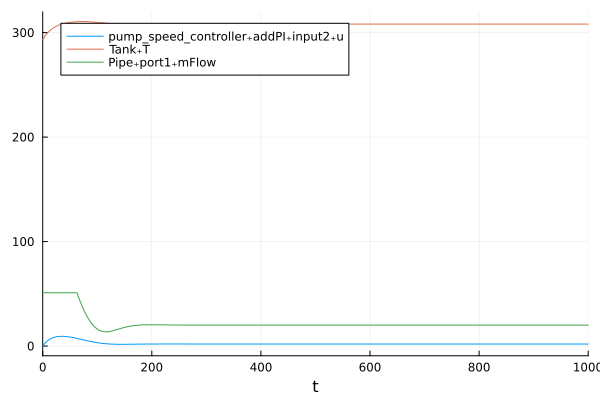

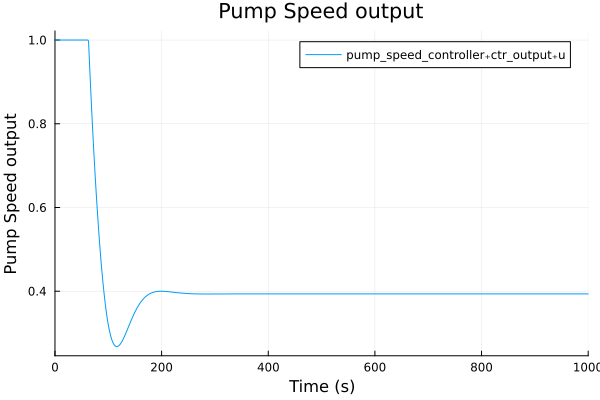

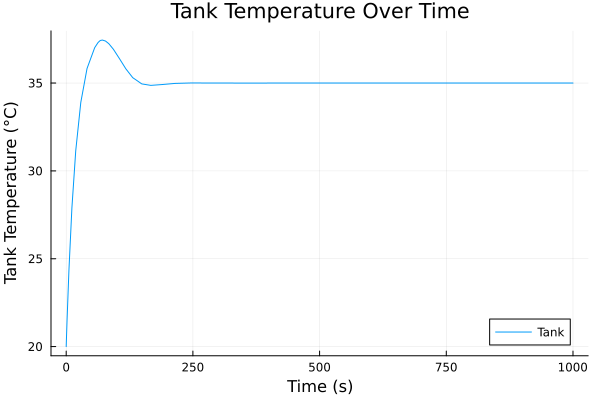

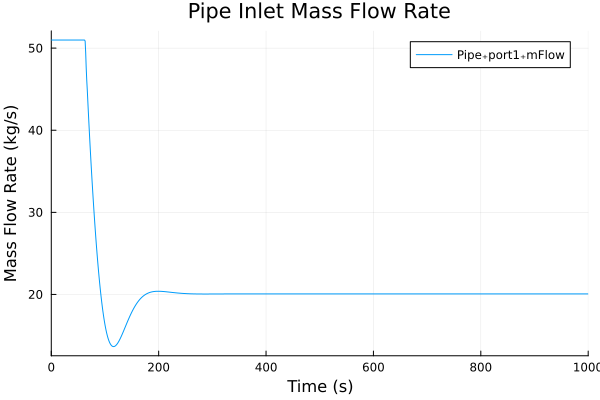

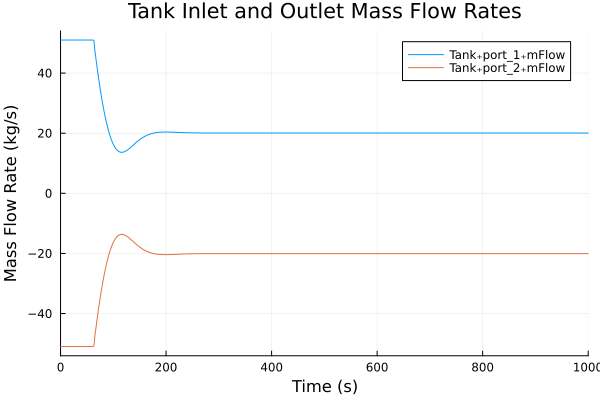

In [47]:
using Plots: plot
display(plot(sol))
# display(plot(sol; idxs = [flux_controller.ctr_output.u], xlabel = "Time (s)", ylabel = "Heat flux output (W)", title = "Heat Flux output"))
display(plot(sol; idxs = [pump_speed_controller.ctr_output.u], xlabel = "Time (s)", ylabel = "Pump Speed output", title = "Pump Speed output"))
display(plot(sol.t, sol[Tank.T] .- 273.15;
     xlabel = "Time (s)", ylabel = "Tank Temperature (°C)",
     label = "Tank", title = "Tank Temperature Over Time"))
display(plot(sol; idxs = [Pipe.port1.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Pipe Inlet Mass Flow Rate"))
display(plot(sol; idxs = [Tank.port_1.mFlow, Tank.port_2.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Tank Inlet and Outlet Mass Flow Rates"))

In [10]:
ts = collect(0.0:10.0:600.0)

vars = [Tank.T, Pipe.port1.mFlow, Tank.port_1.mFlow, Tank.port_2.mFlow]

data = hcat([sol(t; idxs = vars) for t in ts]...)
display(data)
data = permutedims(data)
display(data)
data_with_time = hcat(ts, data)
display(data_with_time)

column_name = ["Time (s)", "Tank Temperature (K)", "Pipe Inlet Mass Flow Rate (kg/s)", "Tank Inlet Mass Flow Rate (kg/s)", "Tank Outlet Mass Flow Rate (kg/s)"]

using DataFrames
df = DataFrame(data_with_time, Symbol.(column_name))
display(df)

UndefVarError: UndefVarError: `sol` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.